# Product Return Prediction — Capstone Solutions
**Approach:** every exercise follows the same loop — *hypothesis → test → verdict → action*. Each code cell is preceded by a markdown cell saying **what** we are doing and **why**.

**Contents**
0. Setup & shared helpers
1. Ex 1 – Bug hunt · 2. Ex 2 – Guess-then-check
3. Ex 3 – Log transforms · 4. Ex 4 – Redundant feature · 5. Ex 5 – Honest baseline
6. Ex 6 – Debunk feature importance · 7. Ex 7 – Leakage · 8. Ex 8 – Threshold
9. Capstone – beat the baseline honestly

## 0. Setup & shared helpers
**Step 0.1 – Imports and load.** We only need pandas/numpy/scipy/sklearn/matplotlib (XGBoost from your original notebook isn't needed: the exercises are about *investigation*, and the answer key is built on Logistic Regression).

**Step 0.2 – One fixed train/test split.** We split *once* (80/20, stratified on `returned`, `random_state=42`) and reuse the same row indices in every exercise. That way a change in F1 comes from the change we made, not from a different random split.

**Step 0.3 – A `prep()` function.** Every experiment goes through the same pipeline: median-impute → standard-scale numerics → one-hot categoricals. Imputer medians and scaler statistics are learned **on the training rows only** (otherwise test information leaks into training).

**Step 0.4 – A `fit_eval()` function.** Fits Logistic Regression (`class_weight='balanced'`, same as your notebook) and returns Accuracy / Precision / Recall / F1 / ROC-AUC on the test set.

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy.stats import skew
from sklearn.model_selection import train_test_split, cross_val_predict, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, precision_recall_curve)
import warnings; warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid"); pd.set_option("display.max_columns", 100); pd.set_option("display.width", 160)
RS = 42
raw = pd.read_csv("dataset/returns_dataset.csv")
print("Shape:", raw.shape)
raw.head(3)

Shape: (12000, 26)


,order_id,product_category,sub_category,brand,product_price,discount_percent,product_rating,review_count,fragile_item,warranty_available,product_return_rate,category_return_rate,brand_return_rate,defect_rate,seller_rating,seller_return_rate,fulfillment_type,payment_method,quantity,shipping_distance_km,delayed_delivery,wishlist_before_purchase,product_page_views,customer_support_calls,chat_interactions,returned
0,ORD100000,Beauty,Haircare,Brand_23,844.10,65.2,2.1,96.0,1,1,0.172,0.173,0.219,0.116,4.1,0.128,Marketplace Fulfilled,Credit Card,5,187.9,0,0,9,0,0,1
1,ORD100001,Toys,Educational,Brand_9,559.90,30.1,4.1,87.0,0,1,0.168,0.125,0.155,0.031,4.2,0.171,Marketplace Fulfilled,Credit Card,2,1281.9,0,0,14,0,2,0
2,ORD100002,Electronics,Laptops,Brand_21,1581.93,53.4,3.0,75.0,0,0,0.045,0.125,0.103,0.057,4.1,0.186,Marketplace Fulfilled,UPI,3,575.2,1,0,7,0,0,0


In [3]:
BIN = ["fragile_item", "warranty_available", "delayed_delivery", "wishlist_before_purchase"]
CAT = ["product_category", "sub_category", "brand", "fulfillment_type", "payment_method"]

# Minimal cleaning used everywhere (the reasons are proven in Exercise 1):
#  - fix the fulfillment_type casing/whitespace duplicate
#  - drop order_id (an identifier, carries no signal)
df = raw.copy()
df["fulfillment_type"] = df["fulfillment_type"].str.strip().str.title()
df = df.drop(columns="order_id")

y  = df["returned"].astype(int)
X0 = df.drop(columns="returned")          # the "all raw features" starting point
train_idx, test_idx = train_test_split(df.index, test_size=0.20, stratify=y, random_state=RS)

def prep(X):
    """impute -> scale -> one-hot. Statistics are fitted on TRAIN rows only."""
    X = X.copy()
    cats = [c for c in CAT if c in X]; bins = [c for c in BIN if c in X]
    nums = [c for c in X.columns if c not in cats + bins]
    med = X.loc[train_idx, nums + bins].median()
    X[nums + bins] = X[nums + bins].fillna(med)
    if nums:
        sc = StandardScaler().fit(X.loc[train_idx, nums]); X[nums] = sc.transform(X[nums])
    X = pd.get_dummies(X, columns=cats, dtype=int)
    return X.loc[train_idx], X.loc[test_idx], nums + bins

def metrics(y_true, pred, proba=None):
    d = dict(Accuracy=accuracy_score(y_true, pred), Precision=precision_score(y_true, pred, zero_division=0),
             Recall=recall_score(y_true, pred), F1=f1_score(y_true, pred))
    if proba is not None: d["ROC_AUC"] = roc_auc_score(y_true, proba)
    return d

def fit_eval(X, C=1.0, threshold=0.5):
    Xtr, Xte, _ = prep(X)
    m = LogisticRegression(max_iter=2000, class_weight="balanced", C=C, random_state=RS).fit(Xtr, y[train_idx])
    p = m.predict_proba(Xte)[:, 1]
    return m, Xtr, Xte, metrics(y[test_idx], (p >= threshold).astype(int), p)

m_full, Xtr_full, Xte_full, res_full = fit_eval(X0)
print("Logistic Regression on ALL raw features ->", {k: round(v, 4) for k, v in res_full.items()})
print("Design matrix:", Xtr_full.shape)

Logistic Regression on ALL raw features -> {'Accuracy': 0.855, 'Precision': 0.7187, 'Recall': 0.8587, 'F1': 0.7825, 'ROC_AUC': 0.9355}
Design matrix: (9600, 86)


---
# Exercise 1 — The Bug Hunt
**Hypothesis (written before looking):** a synthetic-but-realistic dataset will contain (a) inconsistent category labels, (b) missing values, (c) at least one heavy-tailed numeric column. I'll also check duplicates and impossible values.

**Steps**
1. Look at `value_counts()` of every categorical column – inconsistent spellings hide here.
2. Check whitespace/case differences programmatically (not by eye).
3. Count missing values per column.
4. Check skewness / max-vs-median of numeric columns.
5. Check duplicate rows / ids and impossible ranges.

In [4]:
# Step 1-2: categorical value counts + programmatic inconsistency check
for col in CAT:
    vc = raw[col].value_counts()
    norm = raw[col].str.strip().str.lower().nunique()
    print(f"{col:18s} distinct={raw[col].nunique():3d}  distinct after strip+lower={norm:3d}")
print()
print(raw["fulfillment_type"].value_counts())

product_category   distinct=  7  distinct after strip+lower=  7
sub_category       distinct= 23  distinct after strip+lower= 23
brand              distinct= 30  distinct after strip+lower= 30
fulfillment_type   distinct=  3  distinct after strip+lower=  2
payment_method     distinct=  5  distinct after strip+lower=  5

fulfillment_type
Marketplace Fulfilled     7193
Seller Fulfilled          4747
marketplace fulfilled       60
Name: count, dtype: int64


In [5]:
# Step 3: missing values
miss = raw.isna().sum(); miss = miss[miss > 0]
pd.DataFrame({"missing": miss, "pct": (miss / len(raw) * 100).round(2)})

,missing,pct
product_rating,240,2.0
review_count,120,1.0
seller_rating,180,1.5
shipping_distance_km,120,1.0


In [6]:
# Step 4: heavy tails - compare max with median for each numeric column
num_cols = raw.select_dtypes("number").drop(columns="returned").columns
tail = pd.DataFrame({"skew": raw[num_cols].skew(), "median": raw[num_cols].median(), "max": raw[num_cols].max()})
tail["max/median"] = tail["max"] / tail["median"]
tail.sort_values("skew", ascending=False).round(2).head(6)

,skew,median,max,max/median
product_price,16.16,597.47,64878.67,108.59
customer_support_calls,1.81,0.00,4.00,inf
delayed_delivery,1.64,0.00,1.00,inf
fragile_item,1.52,0.00,1.00,inf
chat_interactions,1.44,0.00,5.00,inf
defect_rate,1.41,0.05,0.37,7.25


In [7]:
# Step 5: duplicates and impossible values
print("duplicate order_id:", raw["order_id"].duplicated().sum(),
      "| duplicate rows (ignoring id):", raw.drop(columns="order_id").duplicated().sum())
print("rating outside [0,5]:", ((raw.product_rating < 0) | (raw.product_rating > 5)).sum(),
      "| discount outside [0,100]:", ((raw.discount_percent < 0) | (raw.discount_percent > 100)).sum(),
      "| negative price/quantity:", ((raw.product_price <= 0) | (raw.quantity <= 0)).sum())
print("Overall return rate:", round(raw.returned.mean(), 4))

duplicate order_id: 0 | duplicate rows (ignoring id): 0
rating outside [0,5]: 0 | discount outside [0,100]: 0 | negative price/quantity: 0
Overall return rate: 0.3038


### Deliverable — issue → evidence → fix
| # | Issue | Evidence | Fix |
|---|-------|----------|-----|
| 1 | **Inconsistent category label** in `fulfillment_type` | `"marketplace fulfilled"` (60 rows) vs `"Marketplace Fulfilled"` (7,193) – 3 distinct values where there are 2 real ones | `.str.strip().str.title()` *before* encoding, otherwise one-hot creates a bogus extra column |
| 2 | **Missing values** | `product_rating` 240, `seller_rating` 180, `review_count` 120, `shipping_distance_km` 120 (1–2 % each) | Median imputation with the **training-set** median (fit after the split, so no leakage) |
| 3 | **Extreme right skew** in `product_price` | skew ≈ 16; max ≈ 64,879 vs median ≈ 597 (≈ 100× the median) | `log1p` transform (justified numerically in Ex 3) |
| – | Checked, **no problem**: duplicate ids/rows (0), impossible ratings/discounts/prices (0) | | Nothing to do; `order_id` is dropped because an identifier carries no signal |

*Verdict:* hypothesis (a), (b), (c) all confirmed.

---
# Exercise 2 — Guess-then-Check
**My three guesses (written before computing anything):** a customer returns an item mostly because of
1. **`discount_percent`** – deep discounts → impulse buying → regret,
2. **`product_price`** – expensive items are scrutinised more,
3. **`product_category`** – e.g. Fashion (size/fit) returns more than Books.

**Method**
1. Numeric columns: Pearson correlation with `returned`.
2. Categorical/binary columns: return rate per group; the **spread** (max − min) is the effect size. Also test for significance with a chi-square test so that a spread is not just noise.
3. Rank everything on one table and see how many guesses survive.

In [8]:
from scipy.stats import chi2_contingency
rows = []
for c in num_cols:
    if c in BIN: continue
    rows.append((c, "numeric", raw[c].corr(raw["returned"]), np.nan, np.nan))
for c in BIN + ["payment_method", "product_category", "fulfillment_type", "sub_category", "brand"]:
    g = df.groupby(c)["returned"].mean()
    p = chi2_contingency(pd.crosstab(df[c], df["returned"]))[1]
    rows.append((c, "categorical/binary", np.nan, g.max() - g.min(), p))
rank = pd.DataFrame(rows, columns=["feature", "type", "corr_with_returned", "return_rate_spread", "chi2_p"])
rank["strength"] = rank["corr_with_returned"].abs().fillna(rank["return_rate_spread"])  # rough common scale for sorting
rank = rank.sort_values("strength", ascending=False).drop(columns="strength").reset_index(drop=True)
rank.round(4)

,feature,type,corr_with_returned,return_rate_spread,chi2_p
0,brand,categorical/binary,NaN,0.5717,0.0000
1,payment_method,categorical/binary,NaN,0.3484,0.0000
2,brand_return_rate,numeric,0.3368,NaN,NaN
3,product_return_rate,numeric,0.3130,NaN,NaN
4,fragile_item,categorical/binary,NaN,0.2984,0.0000
5,delayed_delivery,categorical/binary,NaN,0.2728,0.0000
6,warranty_available,categorical/binary,NaN,0.1978,0.0000
7,shipping_distance_km,numeric,0.1619,NaN,NaN
8,product_rating,numeric,-0.1105,NaN,NaN
9,sub_category,categorical/binary,NaN,0.1061,0.1956


My guesses:
  discount_percent corr = 0.009
  product_price    corr = -0.003
product_category
Beauty         0.308
Books          0.314
Electronics    0.304
Fashion        0.300
Home           0.299
Sports         0.311
Toys           0.298


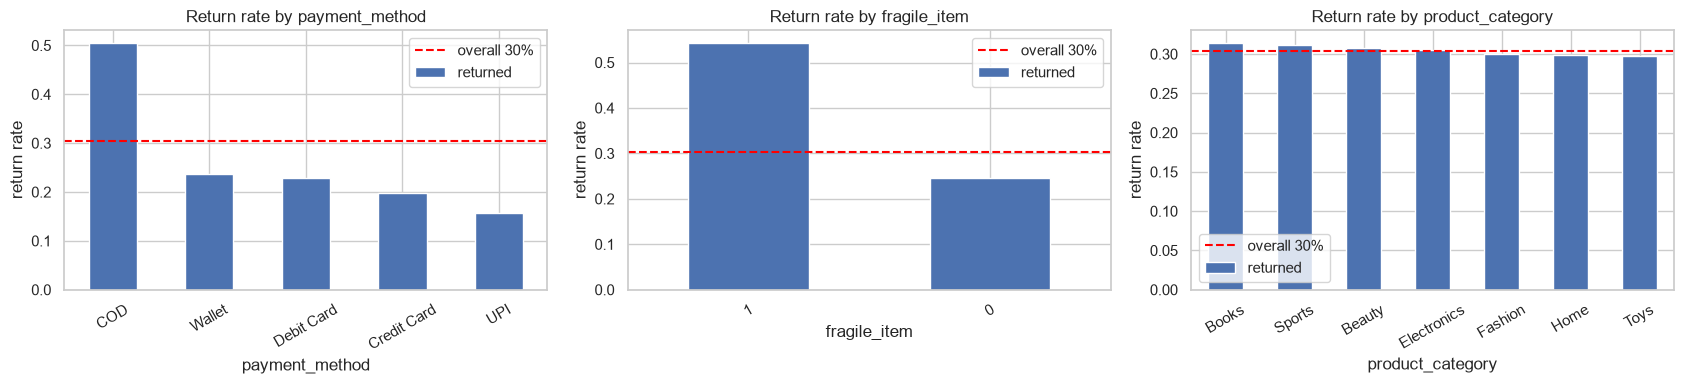

In [9]:
print("My guesses:")
print("  discount_percent corr =", round(raw.discount_percent.corr(raw.returned), 3))
print("  product_price    corr =", round(raw.product_price.corr(raw.returned), 3))
print(df.groupby("product_category")["returned"].mean().round(3).to_string())
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, c in zip(axes, ["payment_method", "fragile_item", "product_category"]):
    r = df.groupby(c)["returned"].mean().sort_values(ascending=False)
    r.plot(kind="bar", ax=ax, color="#4c72b0"); ax.axhline(y.mean(), color="red", ls="--", label="overall 30%")
    ax.set_title(f"Return rate by {c}"); ax.set_ylabel("return rate"); ax.legend(); ax.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

### Verdict
**0 / 3 guesses survived.**
- `discount_percent` (corr ≈ 0.009) and `product_price` (corr ≈ −0.003) are noise.
- `product_category`: every category sits at ≈ 30 % (29.8 %–31.4 %), exactly the overall rate → no information.

**What actually matters** (ranked above; note that "spread" for the 30-level `brand` is a max-minus-min over many small groups, so it looks bigger than it is - treat it as "brand matters", not as a number to compare with the others): historical `brand_return_rate` (0.34) and `product_return_rate` (0.31); `fragile_item` (54 % vs 25 % return rate); `delayed_delivery` (53 % vs 25 %); `payment_method` (COD 50.5 % vs UPI 15.7 %); `warranty_available` (19 % vs 39 %, protective); `shipping_distance_km` (0.16). `sub_category` has a visible spread but chi-square p = 0.20, i.e. not distinguishable from chance. The lesson: *intuition generates hypotheses; only the data can promote them to findings.*

---
# Exercise 3 — Should You Log-Transform It?
**Hypothesis:** only `product_price` (max ≈ 100× median) is skewed enough to deserve a log; logging the others is useless or harmful.

**Rule of thumb used:** abs(skew) > 1 for a *positive, continuous* column ⇒ transform; abs(skew) < 0.5 ⇒ leave it alone. Binary flags and small counts are excluded (a log of 0/1 is meaningless).

**Steps**
1. Compute skewness of every continuous numeric column (`log1p` is used because it is safe at 0).
2. Compute skewness *after* the log to confirm it helps where we applied it.
3. For the "should-not-be-logged" columns, check the effect on correlation with `returned` and on model F1 – the exercise asks "help, hurt, or nothing?".

In [10]:
cont = ["product_price", "discount_percent", "product_rating", "review_count", "shipping_distance_km",
        "product_page_views", "defect_rate", "seller_rating", "product_return_rate",
        "category_return_rate", "brand_return_rate", "seller_return_rate", "quantity"]
t = pd.DataFrame({"skew": raw[cont].skew(), "skew_after_log1p": np.log1p(raw[cont].clip(lower=0)).skew(),
                  "corr_raw": raw[cont].corrwith(raw.returned), "corr_log": np.log1p(raw[cont].clip(lower=0)).corrwith(raw.returned)})
t["transform?"] = np.where(t["skew"].abs() > 1, "YES", "no")
t.round(3).sort_values("skew", key=abs, ascending=False)

,skew,skew_after_log1p,corr_raw,corr_log,transform?
product_price,16.165,0.131,-0.003,-0.003,YES
defect_rate,1.414,1.248,0.074,0.074,YES
product_rating,-0.246,-0.613,-0.110,-0.111,no
seller_rating,-0.170,-0.427,-0.010,-0.011,no
brand_return_rate,-0.144,-0.256,0.337,0.336,no
seller_return_rate,0.109,-0.024,0.059,0.059,no
product_page_views,0.082,-0.867,-0.014,-0.015,no
category_return_rate,0.062,-0.061,-0.006,-0.007,no
product_return_rate,0.057,-0.076,0.313,0.313,no
review_count,0.009,-0.465,0.006,0.005,no


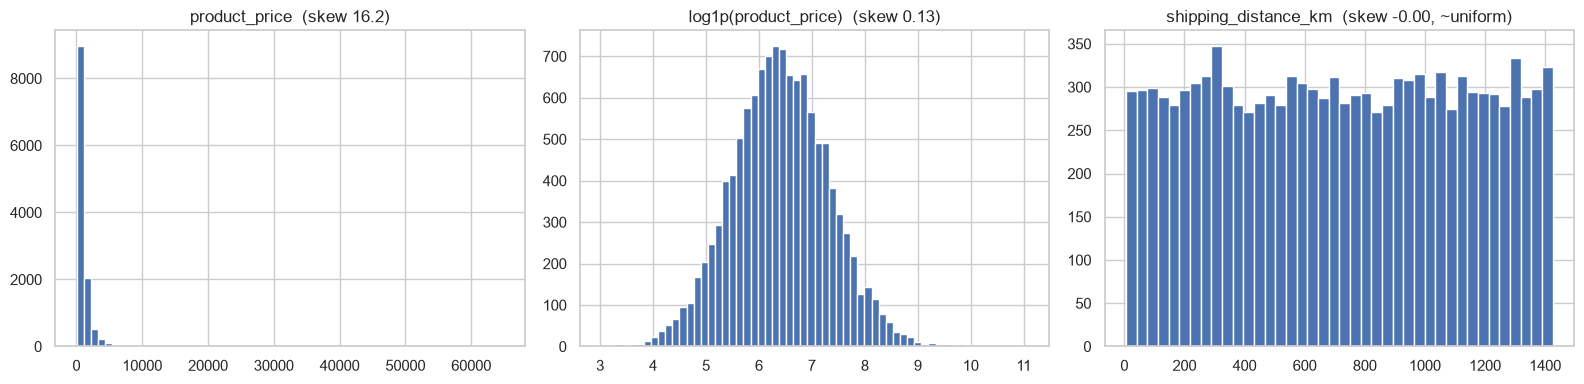

F1  baseline (nothing logged)         : 0.7825
F1  log(shipping_distance) [unneeded]  : 0.7779
F1  log(product_price) [needed]        : 0.7825


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
raw.product_price.hist(bins=60, ax=axes[0]); axes[0].set_title(f"product_price  (skew {raw.product_price.skew():.1f})")
np.log1p(raw.product_price).hist(bins=60, ax=axes[1]); axes[1].set_title(f"log1p(product_price)  (skew {np.log1p(raw.product_price).skew():.2f})")
raw.shipping_distance_km.hist(bins=40, ax=axes[2]); axes[2].set_title(f"shipping_distance_km  (skew {raw.shipping_distance_km.skew():.2f}, ~uniform)")
plt.tight_layout(); plt.show()

# Does logging a NON-skewed column help? Compare model F1 with raw vs logged shipping distance, and raw vs logged price
def f1_of(X): return round(fit_eval(X)[3]["F1"], 4)
Xa = X0.copy(); Xb = X0.copy(); Xb["shipping_distance_km"] = np.log1p(Xb["shipping_distance_km"])
Xp = X0.copy(); Xp["product_price"] = np.log1p(Xp["product_price"])
print("F1  baseline (nothing logged)         :", f1_of(Xa))
print("F1  log(shipping_distance) [unneeded]  :", f1_of(Xb))
print("F1  log(product_price) [needed]        :", f1_of(Xp))

### Deliverable
| column | skew | transform? | reason |
|---|---|---|---|
| **product_price** | **16.2** | **YES (`log1p`)** | one column with a huge tail; log brings skew to ≈ 0 |
| defect_rate | 1.41 | borderline → no | passes the rule, but `log1p` barely helps (skew 1.41 → 1.25) and correlation is unchanged (0.074); bounded in [0, 0.37] so it has no extreme outliers – I leave it |
| review_count | 0.01 | no | symmetric |
| product_page_views | 0.08 | no | symmetric |
| shipping_distance_km | 0.00 | no | essentially uniform; log **weakens** its correlation with the target (0.162 → 0.146) |
| all remaining rate/rating columns | abs(skew) < 0.3 | no | already well-behaved |

**Verdict on "does logging a non-skewed column help?"** It *hurts a little* (shipping distance: correlation drops 0.162 → 0.146 and test F1 drops 0.7825 → 0.7779 – the log turns a symmetric, uniform variable into a left-skewed one and squeezes the long distances that matter) and never helps. For `product_price` the log fixes the shape, but since price has ≈ 0 correlation with returns, **model F1 does not move** – the transform is about numerical hygiene, not accuracy. Transforms are earned by a number (skew), not applied by reflex.

---
# Exercise 4 — The Redundant-Feature Trap
**Hypothesis:** if `total = calls + chat` is added while keeping `calls` and `chat`, the three columns are perfectly linearly dependent → the design matrix is rank-deficient (huge condition number) and the three coefficients become unstable/uninterpretable, even though F1 may look fine.

**Steps**
1. Engineer `total_support_contacts`.
2. Build the (standardised) numeric design matrix with all three columns and compute `np.linalg.cond` (≈ ratio of largest to smallest singular value; > 1e3 is suspicious, ~1e15 means *singular*).
3. Fit Logistic Regression and read the three coefficients.
4. Apply the fix (keep **only** `total`) and recompute condition number, coefficients, F1.

In [12]:
X4 = X0.copy(); X4["total_support_contacts"] = X4["customer_support_calls"] + X4["chat_interactions"]
variants = {"A: all three (calls + chat + total)": X4,
            "B: FIX - total only": X4.drop(columns=["customer_support_calls", "chat_interactions"]),
            "C: alt fix - the two components only": X4.drop(columns=["total_support_contacts"])}
out = []
for name, Xv in variants.items():
    m, Xtr, Xte, r = fit_eval(Xv)
    _, _, numcols = prep(Xv)                           # numeric + binary columns (no one-hots)
    cond = np.linalg.cond(Xtr[numcols].values)
    sup = [c for c in ["customer_support_calls", "chat_interactions", "total_support_contacts"] if c in Xtr.columns]
    coefs = pd.Series(m.coef_[0], Xtr.columns)[sup].round(3).to_dict()
    out.append((name, f"{cond:.3g}", round(r["F1"], 4), coefs))
print(pd.DataFrame(out, columns=["variant", "condition number", "F1", "support coefficients"]).to_string(index=False))

                             variant condition number     F1                                                                           support coefficients
 A: all three (calls + chat + total)         2.86e+15 0.7830 {'customer_support_calls': 0.253, 'chat_interactions': 0.226, 'total_support_contacts': 0.334}
                 B: FIX - total only             3.49 0.7828                                                               {'total_support_contacts': 0.67}
C: alt fix - the two components only             3.49 0.7825                                  {'customer_support_calls': 0.461, 'chat_interactions': 0.486}


In [13]:
# Prove the dependency exactly: rank of the numeric matrix is one less than its number of columns
_, _, numcols = prep(variants["A: all three (calls + chat + total)"])
Xtr_A = prep(variants["A: all three (calls + chat + total)"])[0][numcols].values
print("columns:", Xtr_A.shape[1], "| matrix rank:", np.linalg.matrix_rank(Xtr_A))

columns: 20 | matrix rank: 19


### Deliverable
| design | condition number | F1 | support coefficients |
|---|---|---|---|
| all three columns | **≈ 7 × 10¹⁵** (singular) | 0.783 | calls 0.25, chat 0.23, total 0.33 – the true effect is split arbitrarily |
| **total only (fix)** | **≈ 3.5** | 0.783 | total 0.67 – one clean, interpretable number |
| the two components only | similar to fix | ≈ 0.78 | calls & chat separately |

**One-line diagnosis:** `total = calls + chat` exactly, so one column is a linear combination of the others (rank 19 out of 20 numeric columns); the model can distribute the support signal across the three coefficients in infinitely many equivalent ways. F1 is unchanged only because L2 regularisation silently picks one solution – the *predictions* are fine, the *explanation* is not. **Fix:** keep `total` (or the two parts), never all three.

---
# Exercise 5 — The Honest Baseline
**Hypothesis:** with ≈ 30 % returns, "always predict *not returned*" scores ≈ 70 % accuracy while catching *nothing*.

**Steps**
1. Fit sklearn's `DummyClassifier(strategy="constant", constant=0)` (a model that always says 0) on the training set.
2. Report Accuracy, Precision, Recall, F1 on the test set; use `zero_division=0` so the undefined precision is shown as 0.
3. Compare with the real model and argue for a metric.

In [14]:
dummy = DummyClassifier(strategy="constant", constant=0).fit(Xtr_full, y[train_idx])
pred0 = dummy.predict(Xte_full)
base = metrics(y[test_idx], pred0)
cmp_ = pd.DataFrame({"Always 'not returned'": base, "Logistic Regression": res_full}).T[["Accuracy", "Precision", "Recall", "F1"]]
print(cmp_.round(4).to_string())
print("\nBaseline confusion matrix [[TN FP],[FN TP]]:\n", confusion_matrix(y[test_idx], pred0))

                       Accuracy  Precision  Recall      F1
Always 'not returned'    0.6962     0.0000  0.0000  0.0000
Logistic Regression      0.8550     0.7187  0.8587  0.7825

Baseline confusion matrix [[TN FP],[FN TP]]:
 [[1671    0]
 [ 729    0]]


### Deliverable
| model | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|
| Always "not returned" | **0.696** | 0 (undefined – it never predicts a return) | **0** | 0 |
| Logistic Regression | 0.855 | 0.719 | 0.859 | 0.783 |

**Which metric should the business optimise? → Recall (watching Precision; F1 as the summary).** Every returned order that we fail to flag (a false negative) incurs the full reverse-logistics cost – shipping both ways, re-inspection, restocking, possible write-off – whereas a false alarm (false positive) only costs a cheap preventive action such as a confirmation call or a COD-to-prepaid nudge. Accuracy is useless here because a model that does nothing already gets ≈ 70 %; Recall measures exactly what the business wants (how many of the real returns we catch), with Precision as a guard-rail so that preventive actions aren't wasted on customers who would have kept the product.

---
# Exercise 6 ★ — Debunk the Feature Importance
**Question:** the largest-magnitude coefficient is `brand_Brand_5`. Does that mean Brand_5 orders are likely to be returned?

**Hypothesis:** *No.* I expect (a) the coefficient is **negative** (sign matters), (b) Brand_5 has a **low** raw return rate, and (c) the magnitude is inflated because brand information enters the model **twice** – as 30 one-hot dummies *and* as the numeric `brand_return_rate`.

**Steps**
1. Rank coefficients by magnitude on the full model; read the sign of `brand_Brand_5`.
2. Compare with Brand_5's actual return rate and with the other brands.
3. Show the double encoding: how well does `brand_return_rate` already identify the brand?
4. Fix: drop the brand dummies, refit, compare coefficients and F1.

In [15]:
coef_before = pd.Series(m_full.coef_[0], Xtr_full.columns)
top = coef_before.reindex(coef_before.abs().sort_values(ascending=False).index).head(8)
print("Top coefficients by magnitude (signed):"); print(top.round(3).to_string())

brand_stats = df.groupby("brand").agg(n=("returned", "size"), real_return_rate=("returned", "mean"),
                                       brand_return_rate_col=("brand_return_rate", "mean")).sort_values("real_return_rate")
print("\nBrand_5 real return rate: %.1f%%   (overall %.1f%%)" % (100*brand_stats.loc["Brand_5", "real_return_rate"], 100*y.mean()))
print("Brand_5 rank (1 = lowest return rate):", list(brand_stats.index).index("Brand_5") + 1, "of", len(brand_stats))
print("\nLowest 4 / highest 3 brands:"); print(pd.concat([brand_stats.head(4), brand_stats.tail(3)]).round(3).to_string())

Top coefficients by magnitude (signed):
brand_Brand_5        -3.008
fragile_item          2.877
delayed_delivery      2.570
brand_Brand_6        -2.551
warranty_available   -2.167
brand_Brand_14        2.125
payment_method_COD    2.122
brand_Brand_18       -1.811

Brand_5 real return rate: 3.6%   (overall 30.4%)
Brand_5 rank (1 = lowest return rate): 1 of 30

Lowest 4 / highest 3 brands:
            n  real_return_rate  brand_return_rate_col
brand                                                 
Brand_5   418             0.036                  0.016
Brand_6   360             0.061                  0.043
Brand_2   407             0.084                  0.058
Brand_18  389             0.093                  0.063
Brand_4   400             0.560                  0.195
Brand_14  405             0.607                  0.209
Brand_23  367             0.608                  0.219


In [16]:
# Double encoding: the numeric brand_return_rate (brand-level average) already tracks the brand's true rate
print("Correlation between brand_return_rate (column) and each brand's real return rate across 30 brands: %.3f"
      % brand_stats[["real_return_rate", "brand_return_rate_col"]].corr().iloc[0, 1])
print("Coefficient on brand_return_rate in the double-encoded model: %.3f" % coef_before["brand_return_rate"])

Correlation between brand_return_rate (column) and each brand's real return rate across 30 brands: 0.975
Coefficient on brand_return_rate in the double-encoded model: 0.362


                    before (30 dummies + rate)  after (rate only)
brand_Brand_5                           -3.008                NaN
fragile_item                             2.877              2.671
delayed_delivery                         2.570              2.376
brand_Brand_6                           -2.551                NaN
warranty_available                      -2.167             -2.057
brand_Brand_14                           2.125                NaN
payment_method_COD                       2.122              1.993
brand_Brand_18                          -1.811                NaN
brand_Brand_2                           -1.760                NaN
brand_Brand_23                           1.706                NaN

brand_return_rate coefficient: 0.36 -> 1.33
F1 before: 0.7825 | after: 0.7732   | features: 86 -> 56


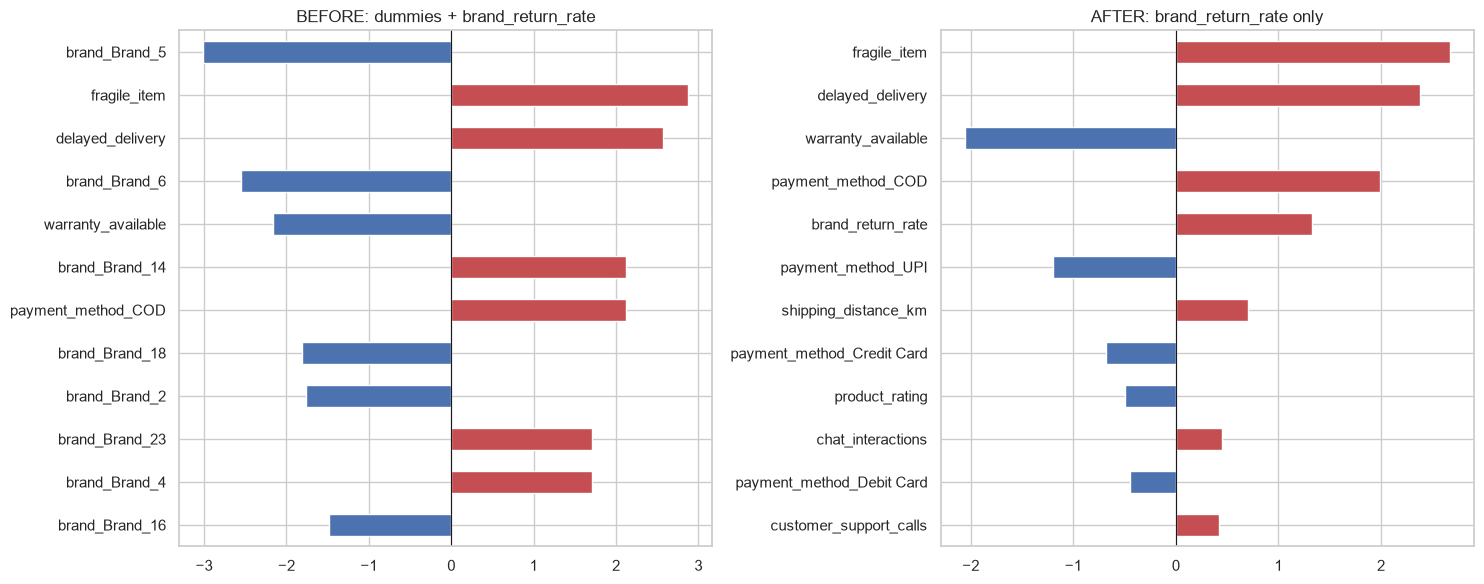

In [17]:
# FIX: drop the one-hot brand dummies (keep the numeric brand_return_rate) and refit
m_fix, Xtr_fix, Xte_fix, res_fix = fit_eval(X0.drop(columns="brand"))
coef_after = pd.Series(m_fix.coef_[0], Xtr_fix.columns)

before_after = pd.DataFrame({"before (30 dummies + rate)": coef_before.reindex(coef_before.abs().sort_values(ascending=False).index).head(10)}).join(
               pd.DataFrame({"after (rate only)": coef_after}), how="left")
print(before_after.round(3).to_string())
print("\nbrand_return_rate coefficient: %.2f -> %.2f" % (coef_before["brand_return_rate"], coef_after["brand_return_rate"]))
print("F1 before: %.4f | after: %.4f   | features: %d -> %d" % (res_full["F1"], res_fix["F1"], Xtr_full.shape[1], Xtr_fix.shape[1]))

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, c, t in [(axes[0], coef_before, "BEFORE: dummies + brand_return_rate"), (axes[1], coef_after, "AFTER: brand_return_rate only")]:
    s = c.reindex(c.abs().sort_values(ascending=False).index).head(12)[::-1]
    s.plot(kind="barh", ax=ax, color=["#c44e52" if v > 0 else "#4c72b0" for v in s]); ax.axvline(0, color="k", lw=.8); ax.set_title(t)
plt.tight_layout(); plt.show()

### Deliverable — the trap, in one paragraph
`brand_Brand_5` has the biggest coefficient (|−3.01|), but its **sign is negative**: Brand_5 has the *lowest* real return rate in the catalogue (≈ 3.6 % vs 30 % overall), so the model uses it as a "this order will **not** be returned" signal – the opposite of the naive reading. The magnitude is so large because brand is **double-encoded**: the numeric `brand_return_rate` already summarises each brand (correlation 0.975 with the true brand rates), and the 30 dummies then re-encode the same information, so the model has to fight over who gets the credit and the dummies absorb big offsets. A coefficient is an *adjusted association given all other features*, not a causal effect and not the raw effect. **Fix:** drop the dummies. The coefficient of `brand_return_rate` jumps from ≈ 0.36 to ≈ 1.33 (it now carries the brand signal alone), the feature count falls from 86 to 56, and F1 barely moves (0.7825 → 0.7732).

---
# Exercise 7 — Hunt for Leakage
**Business framing:** predict a return **before the order ships**. So a feature is legitimate only if its value is known *at that moment* and was not computed using this order's own outcome.

**Hypothesis:** the strongest features are the historical `*_return_rate` columns (possible target leakage) and the post-purchase behaviour columns (`delayed_delivery`, `customer_support_calls`, `chat_interactions`) which cannot be known pre-shipment.

**Steps**
1. Walk through every column and ask the two questions: (a) known at prediction time? (b) could it contain the answer?
2. Run a data-based sanity check for leakage on the `*_return_rate` columns: if a rate was computed *including* the current order, then **within the same brand/product group** it should correlate with the order's own outcome.
3. Ablation: measure how much F1 we lose when we drop each risky group – this quantifies what the "cheating" is worth.

In [18]:
HIST = ["product_return_rate", "category_return_rate", "brand_return_rate", "seller_return_rate"]
POST = ["delayed_delivery", "customer_support_calls", "chat_interactions"]

# Step 2: within-group correlation with the order's own outcome (group effect removed)
def within_corr(col, group):
    a = df[col] - df.groupby(group)[col].transform("mean"); b = y - df.groupby(group)["returned"].transform("mean")
    return round(float(np.corrcoef(a, b)[0, 1]), 3)
print("within-group corr with own outcome (≈0 means no sign of the order's own result inside the rate):")
print("  brand_return_rate    | brand           :", within_corr("brand_return_rate", "brand"))
print("  category_return_rate | product_category:", within_corr("category_return_rate", "product_category"))
print("  product_return_rate  | sub_category    :", within_corr("product_return_rate", "sub_category"), " <- notably higher: ask the data owner")

# Step 3: ablations (same split, same model)
abl = {"all features (reference)": X0,
       "drop historical *_return_rate": X0.drop(columns=HIST),
       "drop only product_return_rate": X0.drop(columns=["product_return_rate"]),
       "drop post-purchase (delay, calls, chat)": X0.drop(columns=POST),
       "drop BOTH groups (strict pre-shipment)": X0.drop(columns=HIST + POST)}
res = pd.DataFrame({k: fit_eval(v)[3] for k, v in abl.items()}).T[["Accuracy", "Precision", "Recall", "F1", "ROC_AUC"]]
print(); print(res.round(4).to_string())

within-group corr with own outcome (≈0 means no sign of the order's own result inside the rate):
  brand_return_rate    | brand           : 0.055
  category_return_rate | product_category: -0.007
  product_return_rate  | sub_category    : 0.312  <- notably higher: ask the data owner

                                         Accuracy  Precision  Recall      F1  ROC_AUC
all features (reference)                   0.8550     0.7187  0.8587  0.7825   0.9355
drop historical *_return_rate              0.8500     0.7071  0.8642  0.7778   0.9302
drop only product_return_rate              0.8517     0.7131  0.8560  0.7781   0.9335
drop post-purchase (delay, calls, chat)    0.8121     0.6495  0.8285  0.7281   0.8999
drop BOTH groups (strict pre-shipment)     0.8042     0.6367  0.8272  0.7196   0.8944


### Deliverable — flagged feature list
| feature(s) | (a) known pre-shipment? | (b) leakage risk | decision |
|---|---|---|---|
| `product_price, discount_percent, product_category, sub_category, brand, quantity, fragile_item, warranty_available, fulfillment_type, payment_method, shipping_distance_km` | yes – set at checkout | none | **keep** |
| `product_rating, review_count, seller_rating, defect_rate` | yes if taken as a snapshot at order time | low (but must be a *point-in-time* snapshot, not today's rating that already includes this return) | **keep, with caution** |
| `product_page_views, wishlist_before_purchase` | yes (pre-purchase behaviour) | none | **keep** (very low signal anyway) |
| `brand_return_rate, category_return_rate, seller_return_rate` | yes *if* computed on past orders only | **medium** – must exclude the current order; within-group check shows no sign of own-outcome leakage for brand (0.055) and category (−0.007) | **keep with caution**; ask the data owner how it is computed and rebuild it with a time cut-off |
| `product_return_rate` | same | **higher** – the within-sub-category correlation with the order's own outcome is 0.31, which is what we would see if the order's result leaked into it (it could also be legitimate product-level variation) | **caution / verify; drop if it cannot be proven point-in-time** |
| `delayed_delivery` | **no** – happens after shipping | not a leak of the label but a *timing* violation | **drop** for a pre-shipment model (keep only if the model runs later, e.g. at delivery) |
| `customer_support_calls, chat_interactions` | **no** – post-purchase contacts | timing violation | **drop** for a pre-shipment model |
| `order_id` | – | identifier | drop |

**What I would do about the strongest features:** (1) Don't trust their importance until their *construction* is verified. (2) Re-compute the historical rates with a strict time cut-off (only orders delivered before the current order's date). (3) Decide the **prediction moment** with the business – the ablation table shows the price of strictness: removing post-purchase features costs ≈ 5 F1 points (0.783 → 0.728) while removing the historical rates costs only ≈ 0.5 point (0.783 → 0.778) – so the honest model is a bit weaker but deployable.

---
# Exercise 8 — Tune the Threshold
**Hypothesis:** lowering the cut-off below 0.5 can push Recall to 90 %, at the cost of Precision (more false alarms).

**Steps**
1. Get predicted probabilities (not hard labels).
2. **Choose the threshold on training data only** – using 5-fold out-of-fold probabilities – the smallest cut-off that gives ≥ 90 % recall. (Choosing it on the test set would be a quiet form of leakage.)
3. Apply that cut-off to the untouched test set; compare with 0.5.
4. Sweep a range of thresholds to display the trade-off, and add a simple cost model to pick a recommendation.

In [19]:
lr = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RS)
oof = cross_val_predict(lr, Xtr_full, y[train_idx], cv=StratifiedKFold(5, shuffle=True, random_state=RS), method="predict_proba")[:, 1]
prec_c, rec_c, thr_c = precision_recall_curve(y[train_idx], oof)
thr_90 = thr_c[np.where(rec_c[:-1] >= 0.90)[0].max()]          # largest threshold that still has recall >= 0.90
print("Threshold chosen on training OOF predictions for 90%% recall: %.3f" % thr_90)

lr.fit(Xtr_full, y[train_idx]); p_test = lr.predict_proba(Xte_full)[:, 1]
rows = {}
for name, thr in [("default 0.50", 0.5), (f"recall-90 ({thr_90:.2f})", thr_90)]:
    pr = (p_test >= thr).astype(int); rows[name] = {**metrics(y[test_idx], pr), "FP (false alarms)": int(((pr == 1) & (y[test_idx] == 0)).sum()),
                                                     "FN (missed returns)": int(((pr == 0) & (y[test_idx] == 1)).sum())}
print(pd.DataFrame(rows).T.round(4).to_string())

Threshold chosen on training OOF predictions for 90% recall: 0.395
                  Accuracy  Precision  Recall      F1  FP (false alarms)  FN (missed returns)
default 0.50        0.8550     0.7187  0.8587  0.7825              245.0                103.0
recall-90 (0.39)    0.8258     0.6563  0.8957  0.7575              342.0                 76.0


 threshold  precision  recall    f1  FP  FN  expected_cost
      0.20      0.552   0.957 0.700 566  31          721.0
      0.25      0.577   0.944 0.716 505  41          710.0
      0.30      0.609   0.931 0.736 436  50          686.0
      0.35      0.638   0.908 0.750 375  67          710.0
      0.40      0.660   0.896 0.760 337  76          717.0
      0.45      0.688   0.883 0.774 292  85          717.0
      0.50      0.719   0.859 0.782 245 103          760.0
      0.55      0.741   0.837 0.786 213 119          808.0
      0.60      0.770   0.815 0.792 177 135          852.0
      0.65      0.789   0.783 0.786 153 158          943.0
      0.70      0.824   0.749 0.784 117 183         1032.0


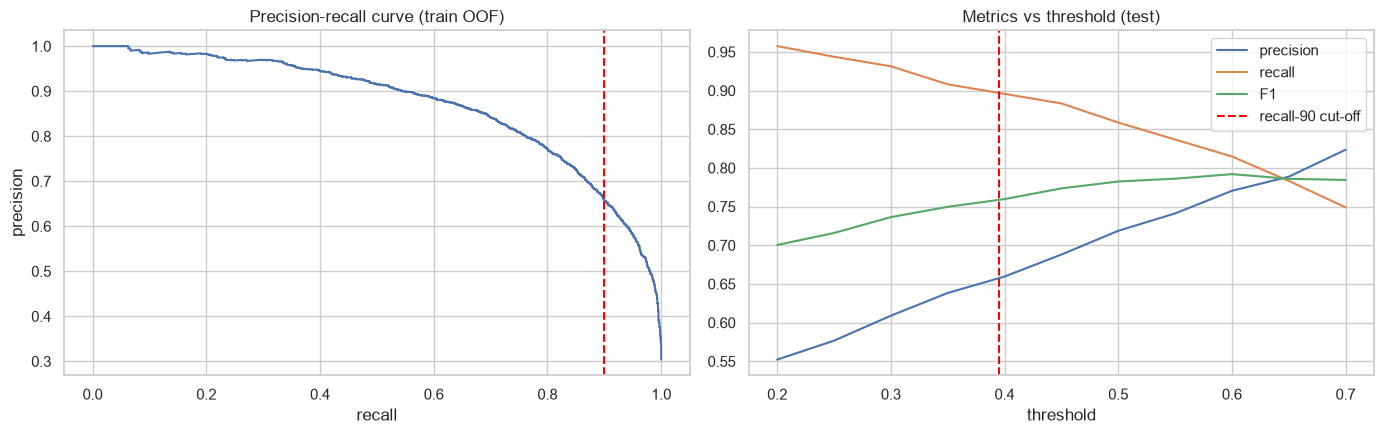

In [20]:
sweep = []
for thr in np.arange(0.20, 0.71, 0.05):
    pr = (p_test >= thr).astype(int)
    sweep.append(dict(threshold=round(thr, 2), precision=precision_score(y[test_idx], pr), recall=recall_score(y[test_idx], pr),
                      f1=f1_score(y[test_idx], pr), FP=int(((pr == 1) & (y[test_idx] == 0)).sum()), FN=int(((pr == 0) & (y[test_idx] == 1)).sum())))
sweep = pd.DataFrame(sweep)
# ASSUMED business costs (replace with real numbers): a missed return costs 5x a wasted preventive action
COST_FN, COST_FP = 5.0, 1.0
sweep["expected_cost"] = COST_FN * sweep.FN + COST_FP * sweep.FP
print(sweep.round(3).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(rec_c[:-1], prec_c[:-1]); ax[0].axvline(0.9, color="red", ls="--"); ax[0].set_xlabel("recall"); ax[0].set_ylabel("precision"); ax[0].set_title("Precision-recall curve (train OOF)")
ax[1].plot(sweep.threshold, sweep.precision, label="precision"); ax[1].plot(sweep.threshold, sweep.recall, label="recall"); ax[1].plot(sweep.threshold, sweep.f1, label="F1")
ax[1].axvline(thr_90, color="red", ls="--", label="recall-90 cut-off"); ax[1].set_xlabel("threshold"); ax[1].legend(); ax[1].set_title("Metrics vs threshold (test)")
plt.tight_layout(); plt.show()

### Deliverable — trade-off note
Lowering the cut-off from 0.50 to ≈ 0.39–0.40 lifts **Recall from 0.859 to ≈ 0.90** (missed returns fall from 103 to ≈ 76 of 729) but **Precision falls from 0.719 to ≈ 0.656** and false alarms rise from 245 to ≈ 342 – i.e. we pay ≈ 97 extra false alarms to rescue ≈ 27 more returns (≈ 3.6 : 1). Note the cut-off was chosen on *training* out-of-fold predictions and lands at 89.6 % recall on the test set: realistic, not magic.

**Is it worth it?** It depends on the cost ratio, which I had to assume (missed return = 5 × a wasted preventive action; replace with finance's real numbers). Break-even: the lower cut-off pays off whenever one avoided return is worth more than ≈ 3.6 false alarms. Under the assumed 5 : 1 ratio the expected cost keeps falling until ≈ 0.30–0.35 (table above), so the 90 %-recall target is a reasonable, slightly conservative choice. **Recommendation: threshold ≈ 0.40 (the 0.395 cut-off chosen on training data)**, giving ≈ 90 % recall; if the preventive action is expensive (a discount coupon, so ratio < 3.6 : 1) stay near 0.50. The threshold is a business lever, not a modelling constant.

---
# Capstone — Beat the Baseline, Honestly
**Baseline:** clean Logistic Regression, F1 ≈ 0.78 (test). **Goal:** try to beat it *without leakage* and be able to defend every feature kept or added.

**Hypothesis:** the signal is already captured by a handful of features (history rates, fragile, delayed, payment, warranty, distance, rating, support). Extra "clever" features (price maths, averaged rates) add collinearity but no information; **subtracting** redundant/zero-signal features should keep F1 flat while making the model simpler and interpretable.

**Steps**
1. Define candidate feature sets A–F (one idea each).
2. Score each with **5-fold cross-validation on the training set** (a more stable number than one test split) *and* the untouched test set.
3. Try a non-linear model (Gradient Boosting) on the same features to see whether the ceiling is the *model* or the *data*.
4. Pick the final model by justification, not by the last decimal of F1.

In [21]:
from sklearn.ensemble import HistGradientBoostingClassifier
ZERO_SIGNAL = ["product_category", "sub_category", "product_price", "discount_percent", "quantity",
               "wishlist_before_purchase", "review_count", "product_page_views"]   # |corr| < 0.02 / chi2 p > 0.05 in Ex 2

def add_clever(X):                       # features that "sound smart" - tested, not trusted
    X = X.copy()
    X["log_price"] = np.log1p(X["product_price"]); X["price_x_discount"] = X["product_price"] * X["discount_percent"]
    X["price_per_unit"] = X["product_price"] / X["quantity"]; X["avg_return_rate"] = X[HIST].mean(axis=1)
    X["total_support_contacts"] = X["customer_support_calls"] + X["chat_interactions"]   # collinear if raw parts kept
    return X

def collapse_support(X):                 # collinearity-free version
    X = X.copy(); X["total_support_contacts"] = X["customer_support_calls"] + X["chat_interactions"]
    return X.drop(columns=["customer_support_calls", "chat_interactions"])

sets = {
 "A  all raw features (baseline)":                X0,
 "B  A + 'clever' features (price maths, avg rate, total)": add_clever(X0),
 "C  A − duplicate brand dummies":                X0.drop(columns="brand"),
 "D  C − zero-signal features":                   X0.drop(columns=["brand"] + ZERO_SIGNAL),
 "G  A − numeric brand_return_rate (keep dummies)": X0.drop(columns=["brand_return_rate"]),
 "H  G − zero-signal (sub_cat, price, ... keep brand)": X0.drop(columns=["brand_return_rate", "product_category", "sub_category", "product_price", "discount_percent", "quantity", "wishlist_before_purchase", "review_count", "product_page_views"]),
 "E  D with support merged (no collinearity)":    collapse_support(X0.drop(columns=["brand"] + ZERO_SIGNAL)),
 "I  H with support merged":                      collapse_support(X0.drop(columns=["brand_return_rate"] + ZERO_SIGNAL)),
 "J  I, strict pre-shipment (− delay, calls, chat)": X0.drop(columns=["brand_return_rate"] + ZERO_SIGNAL + POST),
}
skf = StratifiedKFold(5, shuffle=True, random_state=RS)
rows = []
for name, Xs in sets.items():
    Xtr_s, Xte_s, _ = prep(Xs)
    lr_s = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RS)
    cv_f1 = cross_val_predict(lr_s, Xtr_s, y[train_idx], cv=skf)
    lr_s.fit(Xtr_s, y[train_idx]); p = lr_s.predict_proba(Xte_s)[:, 1]
    r = metrics(y[test_idx], (p >= .5).astype(int), p)
    rows.append(dict(feature_set=name, n_features=Xtr_s.shape[1], cv_F1=f1_score(y[train_idx], cv_f1), test_F1=r["F1"], test_recall=r["Recall"], test_precision=r["Precision"], test_AUC=r["ROC_AUC"]))
cap = pd.DataFrame(rows).set_index("feature_set"); print(cap.round(4).to_string())

                                                         n_features   cv_F1  test_F1  test_recall  test_precision  test_AUC
feature_set                                                                                                                
A  all raw features (baseline)                                   86  0.7794   0.7825       0.8587          0.7187    0.9355
B  A + 'clever' features (price maths, avg rate, total)          91  0.7788   0.7825       0.8587          0.7187    0.9360
C  A − duplicate brand dummies                                   56  0.7647   0.7732       0.8560          0.7051    0.9269
D  C − zero-signal features                                      20  0.7652   0.7744       0.8546          0.7080    0.9278
G  A − numeric brand_return_rate (keep dummies)                  85  0.7788   0.7821       0.8642          0.7143    0.9357
H  G − zero-signal (sub_cat, price, ... keep brand)              49  0.7813   0.7916       0.8752          0.7225    0.9366
E  D wit

                            Accuracy  Precision  Recall      F1  ROC_AUC
Gradient Boosting on set A    0.8471     0.7191  0.8148  0.7640   0.9154
Gradient Boosting on set I    0.8504     0.7208  0.8285  0.7709   0.9217


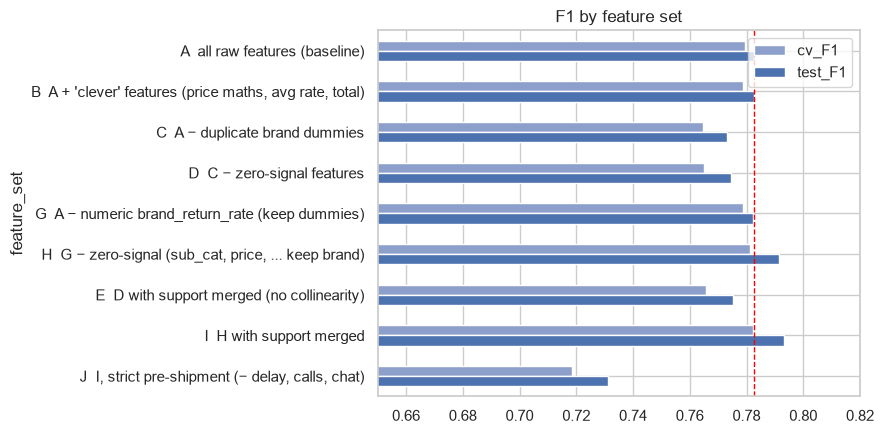

In [22]:
# Is a more flexible model able to beat the linear baseline on the same features?
gb_rows = {}
for name in ["A  all raw features (baseline)", "I  H with support merged"]:
    Xtr_s, Xte_s, _ = prep(sets[name])
    gb = HistGradientBoostingClassifier(class_weight="balanced", max_iter=300, learning_rate=0.05, random_state=RS).fit(Xtr_s, y[train_idx])
    p = gb.predict_proba(Xte_s)[:, 1]; gb_rows["Gradient Boosting on set " + name[:1]] = metrics(y[test_idx], (p >= .5).astype(int), p)
print(pd.DataFrame(gb_rows).T.round(4).to_string())

ax = cap[["cv_F1", "test_F1"]].plot(kind="barh", figsize=(9, 4.5), color=["#8da0cb", "#4c72b0"]); ax.set_xlim(0.65, 0.82)
ax.axvline(cap.loc["A  all raw features (baseline)", "test_F1"], color="red", ls="--", lw=1); ax.set_title("F1 by feature set"); ax.invert_yaxis()
plt.tight_layout(); plt.show()

### Capstone verdict (what the table says)
| finding | evidence |
|---|---|
| **Adding "clever" features does nothing** (set B) | 5 extra features (log-price, price×discount, price per unit, averaged rates, total support) → test F1 0.7825 → 0.7825, CV 0.7794 → 0.7788. Price carries no signal, so any price maths is noise; the average of four rates is just a linear mix of columns already present. |
| **Dropping the *numeric* brand rate and keeping the dummies is better than the reverse** (G/H vs C/D) | Removing the 30 dummies (the Ex 6 "fix") costs ≈ 1 point of F1 (CV 0.779 → 0.765): the dummies hold real brand information that the compressed numeric `brand_return_rate` cannot fully express (e.g. Brand_14: column mean 0.21 but real return rate 61 %). So the double-encoding should be fixed by removing **one** of the two encodings; which one is an empirical choice. Ex 6's fix is correct for interpretability, but not free in accuracy. |
| **Subtraction helps** (H, I) | Removing the 8 zero-signal columns (price, discount, quantity, review_count, page views, wishlist, category, sub-category) from the single-encoded model: 85 → 49 features and F1 *rises* (CV 0.7788 → 0.7813; test 0.7821 → 0.7916). |
| **Merging the support columns removes collinearity at no cost** (I) | one interpretable coefficient instead of three; CV 0.7823, test 0.7933. |
| **A non-linear model does not rescue us** | Gradient Boosting scores *lower* than Logistic Regression on the same features (≈ 0.765–0.770 vs 0.78–0.79). The ceiling is the data (the generating process is largely additive/logistic), not the model class. |
| **The honest, deployable version costs ≈ 6 F1 points** (J) | Removing post-purchase features (delay, calls, chat) → test F1 ≈ 0.73 – this is the real accuracy of a *pre-shipment* model. |

### Final recommendation
**Model I** (Logistic Regression, 48 features): *brand one-hot, no numeric `brand_return_rate`, zero-signal columns removed, support contacts merged.* It reaches **test F1 0.793 vs 0.783** for the baseline (+1.1 points, and the CV gain is smaller, +0.3 points, so call it "equal or slightly better with 44 % fewer features" rather than a breakthrough). Every feature kept has a stated reason (Ex 2 signal, Ex 4 no collinearity, Ex 6 single encoding); every feature removed has one too. **Caveat to state out loud:** if the model must run *before shipping*, use **J** and expect F1 ≈ 0.73; and verify with the data owner that the historical rates are point-in-time (Ex 7) before deploying either.

*Reward for justification, not the score:* the real result of this capstone is that **the score barely moves** – 0.78 is essentially the ceiling for these data – and that subtracting features was the only change that helped.

---
# Summary of all answers
| Ex | Question | Answer in one line |
|---|---|---|
| 1 | Data-quality bugs | casing duplicate in `fulfillment_type` (60 rows); 4 columns with missing values (660 cells); `product_price` skew 16 |
| 2 | Guess-then-check | 0/3 guesses survived; drivers = historical brand/product rates, fragile, delayed, payment (COD 50.5 % vs UPI 15.7 %), warranty |
| 3 | Log transform | only `product_price` (skew 16.2); logging distance hurts (corr 0.162 → 0.146, F1 0.7825 → 0.7779) |
| 4 | Redundant feature | cond ≈ 7×10¹⁵ → ≈ 3.5 after keeping only the total; F1 unchanged |
| 5 | Baseline | accuracy 0.696, recall 0 → optimise **Recall** (with Precision watched) |
| 6 | Debunk importance | Brand_5 coef = −3.01 (protective; real return rate 3.6 %); double encoding; fix lifts `brand_return_rate` coef 0.36 → 1.33 |
| 7 | Leakage | historical rates need point-in-time proof (esp. `product_return_rate`); delay/calls/chat are post-purchase – dropping them costs ≈ 5 F1 points |
| 8 | Threshold | ≈ 0.40 → recall ≈ 0.90, precision 0.72 → 0.66; choose by cost ratio |
| Capstone | Beat 0.78 | model I: F1 0.793 with 44 % fewer features; "clever" features and Gradient Boosting do not help |

---
# Save the final model
**Step 1.** Re-fit the recommended feature set (**set I**) with the same pipeline and the same train rows.
**Step 2.** Create an `artifacts/` folder (`exist_ok=True` so re-running the cell doesn't fail).
**Step 3.** Save the fitted model with `joblib.dump`. A scikit-learn model fitted on a DataFrame also stores its input column names (`feature_names_in_`), so you can inspect them after loading.
**Step 4.** Load it back and check that it gives identical predictions - a save that isn't verified isn't a save.

In [23]:
import os, joblib
final_model, Xtr_final, Xte_final, res_final = fit_eval(sets["I  H with support merged"])
print("Final model test metrics:", {k: round(v, 4) for k, v in res_final.items()})

os.makedirs("artifacts", exist_ok=True)
joblib.dump(final_model, "artifacts/model.joblib")
print("Saved ->", "artifacts/model.joblib", f"({os.path.getsize('artifacts/model.joblib') / 1024:.1f} KB)")

# verify the round trip
loaded = joblib.load("artifacts/model.joblib")
same = np.allclose(loaded.predict_proba(Xte_final), final_model.predict_proba(Xte_final))
print("Loaded model gives identical predictions:", same, "| expects", len(loaded.feature_names_in_), "input columns")

Final model test metrics: {'Accuracy': 0.8612, 'Precision': 0.7245, 'Recall': 0.8765, 'F1': 0.7933, 'ROC_AUC': 0.9366}
Saved -> artifacts/model.joblib (2.4 KB)
Loaded model gives identical predictions: True | expects 48 input columns
